<div style="display:flex; align-items:center; gap:18px; text-align:left">
  <img src="https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/assets/logo_ust.png" width="100">
  <div>
    <p>Diplomado en Inteligencia Artificial para los Negocios</p>
    <p>Facultad de Ingeniería y Negocios</p>
    <p>Módulo 2: Fundamentos de Machine Learning y herramientas Low Code</p>
    <p>Semana 07: Ejercicios de repaso 3 · Clase 7 (solución comentada)</p>
  </div>
</div>

# Ejercicios de repaso 3 · Clase 7: Introducción a Forecasting — Solución comentada

Este notebook resuelve los ejercicios de repaso 3 de la **Clase 7**. Cada ejercicio trae:

1. **El código de la solución**, con comentarios línea a línea redactados de forma clara y directa.
2. **Por qué se hizo así**: la razón de cada decisión, la lectura esperada del resultado y el enlace directo
   a la diapositiva correspondiente del curso para profundizar.
3. En los ejercicios clave, un **prompt para pedirle a una IA que les ayude a corregir su código**.
   Está pensado para que la IA **revise lo que ustedes escribieron** y explique el error, no para que
   escriba todo de nuevo.

Úsenlo **después** de intentar cada ejercicio: comparar su intento con la solución es lo que más enseña.

## Preparación del entorno

Instalamos `statsforecast` y `utilsforecast` (la salida queda oculta) y dejamos lista la configuración general.

In [1]:
%%capture
!pip install -q "statsforecast==2.0.3" "utilsforecast==0.2.15" plotly ipywidgets

In [2]:
%matplotlib inline
import os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, AutoETS, AutoARIMA
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, mape

# en Colab los datos se leen del repo público; en local, desde ../datasets/
REPO = 'https://raw.githubusercontent.com/sebastiancontz/ust-fundamentos-machine-learning-colab/main/ediciones/2026/datasets/'
BASE = '../datasets/' if os.path.exists('../datasets') else REPO

## Bloque A · Qué es una serie de tiempo y exploración (la anatomía)

**Caso:** tráfico aéreo de pasajeros en Chile (`trafico_aereo_cl.csv`, datos oficiales de la Junta de
Aeronáutica Civil - JAC). Cada fila registra el número de pasajeros que volaron en un mes determinado.

En una serie de tiempo el **orden de las filas es información**: no se pueden barajar.

In [3]:
df = pd.read_csv(BASE + 'trafico_aereo_cl.csv', parse_dates=['ds'])
print('Filas y columnas:', df.shape)
df.head()

Filas y columnas: (576, 3)


,unique_id,ds,y
0,internacional,2010-01-01,276185
1,internacional,2010-02-01,216808
2,internacional,2010-03-01,151591
3,internacional,2010-04-01,172548
4,internacional,2010-05-01,181973


### Ejercicio A1 · El formato estándar: unique_id, ds, y

Muestren cuántas **series distintas** hay en `unique_id`, cuál es el **rango de fechas**
(fecha mínima y máxima en `ds`) y comprueben si hay valores nulos.
¿Por qué herramientas modernas como StatsForecast exigen este **formato largo** de tres columnas en vez
de una tabla ancha con una columna por serie?

In [4]:
print('Meses registrados por cada serie:')
display(df['unique_id'].value_counts())

print('\nRango de fechas:')
print('Desde:', df['ds'].min().strftime('%Y-%m'), '| Hasta:', df['ds'].max().strftime('%Y-%m'))

print('\nValores faltantes:')
print(df.isna().sum())

Meses registrados por cada serie:


unique_id
internacional    192
nacional         192
total            192
Name: count, dtype: int64


Rango de fechas:
Desde: 2010-01 | Hasta: 2025-12

Valores faltantes:
unique_id    0
ds           0
y            0
dtype: int64


**Por qué se hizo así**

- **Estructura estándar de StatsForecast:**
  - `unique_id`: identificador de la serie (permite tener miles de productos, tiendas o rutas en una sola tabla).
  - `ds`: marca de tiempo (*timestamp* o fecha).
  - `y`: valor numérico observado (demanda, pasajeros, ventas).
- **Ventaja del formato largo frente al formato ancho:** en una tabla ancha agregar una serie nueva exige
  crear una columna, lo que rompe los esquemas de bases de datos. En formato largo, simplemente se agregan
  filas hacia abajo. Además, permite a librerías de alto rendimiento procesar **todas las series en paralelo**
  con una sola línea de código.
- **Datos limpios:** la serie está completa, con 192 meses por serie (16 años) sin huecos ni faltantes.

Para profundizar en la estructura de datos para pronósticos temporales, consulten la diapositiva [El formato estándar: unique_id, ds e y](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/el-formato-estándar-unique_id-ds-e-y) de la Clase 7.

**Si su código no funciona: prompt para que una IA les ayude a corregirlo**

Copien el prompt, reemplacen lo que está entre corchetes y péguenlo en su asistente de IA. Pidan una corrección explicada, no una solución nueva: el objetivo es entender qué falló.

```text
Estoy aprendiendo forecasting con pandas y StatsForecast en Google Colab.
Tengo un DataFrame `df` con las columnas `unique_id`, `ds` (fechas) e `y` (pasajeros).
Quiero verificar el rango de fechas, cuántas series distintas hay y si existen valores nulos.

Este es mi código:
[pegar aquí su código]

Explícame si mi código es eficiente y por qué en forecasting se utiliza esta convención de nombres (`unique_id`, `ds`, `y`).
```

### Ejercicio A2 · Leer la anatomía a ojo: tendencia, estacionalidad y quiebres

Dibujen un gráfico de línea interactivo con Plotly de la serie **`total`** a lo largo de todo el tiempo.
Identifiquen a simple vista:
1. La **tendencia** antes del año 2020.
2. La **estacionalidad**: ¿en qué mes del año se produce sistemáticamente el mayor número de pasajeros?
3. El **cambio estructural**: ¿qué ocurrió a partir de marzo de 2020? ¿Puede un modelo de forecasting
    anticipar un evento como ese?

In [5]:
# filtramos la serie total para ver la historia completa
serie_total = df[df['unique_id'] == 'total']
fig = px.line(serie_total, x='ds', y='y',
              title='Tráfico aéreo de pasajeros en Chile (Serie Total)',
              labels={'ds': 'Fecha', 'y': 'Pasajeros mensuales'})
fig.show()

**Por qué se hizo así**

- **Tendencia de fondo:** entre 2010 y 2019 se observa un crecimiento sostenido, impulsado por el
  ingreso de aerolíneas de bajo costo y la expansión económica (casi se duplican los pasajeros).
- **Estacionalidad anual:** el peak ocurre con regularidad de reloj **cada enero**, coincidiendo con las
  vacaciones de verano en Chile, seguido de un valle en mayo-junio. La estacionalidad es predecible porque
  sigue el calendario humano.
- **Cambio estructural (marzo 2020):** la pandemia de COVID-19 derrumbó el tráfico aéreo casi a cero en
  cuestión de semanas.
- **Límite fundamental:** ningún modelo estadístico ni de IA puede predecir un quiebre estructural antes de
  que ocurra, porque el pasado no contiene pistas de ese evento. Pero una vez que el quiebre ocurre, el
  analista debe decidir si entrena con toda la historia o solo con la nueva normalidad posterior.

Para revisar cómo descomponer visual y analíticamente los componentes de una serie temporal, revisen la diapositiva [Toda serie combina cuatro componentes](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/toda-serie-combina-cuatro-componentes) de la Clase 7 (disponible a continuación de forma interactiva):

In [6]:
# diapositiva interactiva de la clase
from IPython.display import IFrame
IFrame('https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/toda-serie-combina-cuatro-componentes', width='100%', height=480)

## Bloque B · Baselines y modelos estadísticos automáticos

Un modelo sofisticado solo tiene sentido si **supera a una regla simple**.
En este bloque enfrentamos las líneas base (*baselines*) contra modelos estadísticos automáticos.

### Ejercicio B1 · Las líneas base: Naive vs SeasonalNaive

Filtren la tabla para trabajar con la serie **`nacional`**.
Configuren un objeto `StatsForecast` con frecuencia mensual (`freq='MS'`) que contenga dos *baselines*:
- `Naive()`: predice que el próximo mes será exactamente igual al último mes observado ("mañana igual a hoy").
- `SeasonalNaive(season_length=12)`: predice que el próximo mes será igual al mismo mes del año anterior.
Generen un pronóstico a **12 meses** (`h=12`). ¿Cuál de los dos baselines reproduce las ondas del verano?
¿Por qué la regla del curso dice que cualquier modelo complejo debe ganarle a estas líneas base?

,unique_id,ds,Naive,SeasonalNaive
0,nacional,2026-01-01,711696.0,805285.0
1,nacional,2026-02-01,711696.0,763051.0
2,nacional,2026-03-01,711696.0,716515.0
3,nacional,2026-04-01,711696.0,614899.0
4,nacional,2026-05-01,711696.0,600633.0
5,nacional,2026-06-01,711696.0,600571.0


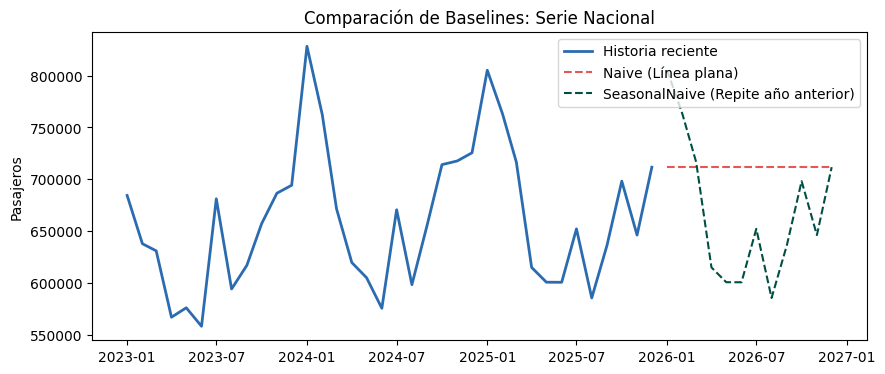

In [7]:
df_nac = df[df['unique_id'] == 'nacional']

# configuramos los dos baselines: Naive y SeasonalNaive (12 meses por ciclo anual)
sf_base = StatsForecast(
    models=[Naive(), SeasonalNaive(season_length=12)],
    freq='MS'   # inicio de cada mes
)

pron_base = sf_base.forecast(df=df_nac, h=12)
display(pron_base.head(6))

# comparamos los últimos 3 años reales contra las proyecciones de ambos baselines
historia_reciente = df_nac.tail(36)
plt.figure(figsize=(10, 4))
plt.plot(historia_reciente['ds'], historia_reciente['y'], label='Historia reciente', color='#2b6cb0', lw=2)
plt.plot(pron_base['ds'], pron_base['Naive'], label='Naive (Línea plana)', color='#E45756', ls='--')
plt.plot(pron_base['ds'], pron_base['SeasonalNaive'], label='SeasonalNaive (Repite año anterior)', color='#004F45', ls='--')
plt.title('Comparación de Baselines: Serie Nacional'); plt.ylabel('Pasajeros'); plt.legend(); plt.show()

**Por qué se hizo así**

- **Naive produce una línea recta horizontal:** toma el último valor conocido y lo repite para los 12
  meses. Ignora la estacionalidad, pero en horizontes cortos (h=1) es una referencia muy dura de batir.
- **SeasonalNaive reproduce las ondas:** proyecta que el próximo enero será idéntico al enero anterior.
  Capta perfectamente el ritmo estacional sin estimar ningún parámetro.
- **La regla de oro:** si un modelo complejo (como una red neuronal o un ensamble) no logra superar a
  `SeasonalNaive` en una serie estacional, **no debe usarse en producción**. Un baseline no cuesta nada de
  cómputo y no requiere mantenimiento: lo complejo debe justificar su costo con mejor precisión.

Para entender por qué los modelos ingenuos fijan la exigencia mínima en cualquier proyecto de predicción, revisen la diapositiva [La línea base fija la exigencia mínima](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/la-línea-base-fija-la-exigencia-mínima) de la Clase 7.

**Si su código no funciona: prompt para que una IA les ayude a corregirlo**

Copien el prompt, reemplacen lo que está entre corchetes y péguenlo en su asistente de IA. Pidan una corrección explicada, no una solución nueva: el objetivo es entender qué falló.

```text
Estoy usando StatsForecast en Google Colab con datos mensuales de pasajeros aéreos.
Tengo un subconjunto `df_nac` y quiero comparar los modelos `Naive` y `SeasonalNaive(season_length=12)` a 12 meses.

Este es mi código:
[pegar aquí su código]

Explícame por qué SeasonalNaive necesita `season_length=12` y cómo interpretar el gráfico resultante.
```

### Ejercicio B2 · Modelos estadísticos automáticos con StatsForecast

Agreguen al objeto `StatsForecast` los modelos automáticos **`AutoETS(season_length=12)`** (suavizado
exponencial que aprende nivel, tendencia y estacionalidad) y **`AutoARIMA(season_length=12)`** (que analiza
la correlación entre los períodos recientes).
Entrenen los 4 modelos (Naive, SeasonalNaive, AutoETS y AutoARIMA) para la serie nacional en una sola
llamada a `forecast(df=df_nac, h=12)`. Muestren la tabla resultante.
¿Qué significa el prefijo **`Auto`** en estos modelos y por qué es una ventaja para el enfoque *low-code*?

In [8]:
# sumamos AutoETS y AutoARIMA a los dos baselines
modelos = [
    Naive(),
    SeasonalNaive(season_length=12),
    AutoETS(season_length=12),
    AutoARIMA(season_length=12)
]

sf = StatsForecast(models=modelos, freq='MS')
pron_todos = sf.forecast(df=df_nac, h=12)

print('Pronóstico de los 4 modelos para los primeros 6 meses:')
display(pron_todos.head(6))

Pronóstico de los 4 modelos para los primeros 6 meses:


,unique_id,ds,Naive,SeasonalNaive,AutoETS,AutoARIMA
0,nacional,2026-01-01,711696.0,805285.0,789906.9375,821107.8125
1,nacional,2026-02-01,711696.0,763051.0,750180.9375,777281.4375
2,nacional,2026-03-01,711696.0,716515.0,668596.0000,701296.5000
3,nacional,2026-04-01,711696.0,614899.0,576903.8750,609039.0000
4,nacional,2026-05-01,711696.0,600633.0,602797.2500,610053.1250
5,nacional,2026-06-01,711696.0,600571.0,602984.5000,594226.6250


**Por qué se hizo así**

- **Qué hace AutoETS (Error, Trend, Seasonal):** descompone la serie en nivel, tendencia y estacionalidad,
  dando más peso a los meses recientes mediante un promedio ponderado exponencial.
- **Qué hace AutoARIMA:** modela la serie mirando sus propios desfases temporales (autocorrelación) y los
  errores de predicción pasados.
- **El prefijo `Auto`:** en la estadística tradicional, configurar un modelo ARIMA requería graficar funciones
  de autocorrelación (ACF/PACF), aplicar diferenciaciones a mano y probar docenas de órdenes (p, d, q).
  `AutoARIMA` y `AutoETS` prueban automáticamente múltiples combinaciones de parámetros y eligen la mejor
  mediante criterios de información (como AIC).
- **Enfoque low-code:** en vez de pasar horas afinando ecuaciones, el analista ejecuta los modelos en una
  línea y dedica su tiempo a **validar, interpretar y decidir**.

Para profundizar en la formulación de modelos exponenciales y autoregresivos, consulten la diapositiva [ETS suaviza el pasado; ARIMA usa errores](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/ets-suaviza-el-pasado-arima-usa-errores) de la Clase 7.

## Bloque C · Validación temporal y métricas

En Machine Learning tabular barajábamos las filas al azar (k-fold).
En series de tiempo **barajar es trampa**: no podemos usar datos de 2024 para predecir 2023.
En este bloque aprendemos a validar respetando la flecha del tiempo con **ventanas móviles**.

### Ejercicio C1 · Validación con ventanas móviles (prohibido barajar)

Ejecuten la validación cruzada temporal con `sf.cross_validation` sobre la serie nacional para un
horizonte de **12 meses** (`h=12`), usando **2 ventanas** (`n_windows=2`) y un salto de 12 meses
(`step_size=12`).
Muestren las primeras filas del resultado `cv`. Observen la columna `cutoff`: ¿qué representa esa fecha?
¿Por qué este método simula con fidelidad la realidad operativa de un analista?

In [9]:
# validación temporal con 2 ventanas de 12 meses (prohibido barajar fechas)
cv = sf.cross_validation(df=df_nac, h=12, n_windows=2, step_size=12)

print('Tamaño del resultado de validación:', cv.shape)
print('Fechas de corte (cutoffs evaluados):', cv['cutoff'].unique())
display(cv.head(6))

Tamaño del resultado de validación: (24, 8)
Fechas de corte (cutoffs evaluados): <DatetimeArray>
['2023-12-01 00:00:00', '2024-12-01 00:00:00']
Length: 2, dtype: datetime64[ns]


,unique_id,ds,cutoff,y,Naive,SeasonalNaive,AutoETS,AutoARIMA
0,nacional,2024-01-01,2023-12-01,828407.0,694249.0,684412.0,764483.9375,754316.0625
1,nacional,2024-02-01,2023-12-01,762589.0,694249.0,637795.0,733599.1875,716013.0625
2,nacional,2024-03-01,2023-12-01,671560.0,694249.0,630906.0,665083.3750,628878.4375
3,nacional,2024-04-01,2023-12-01,619627.0,694249.0,566843.0,582441.5000,524706.7500
4,nacional,2024-05-01,2023-12-01,604966.0,694249.0,575948.0,593826.0625,538246.4375
5,nacional,2024-06-01,2023-12-01,575473.0,694249.0,558090.0,581763.8125,518205.2500


**Por qué se hizo así**

- **La columna `cutoff` (fecha de corte):** marca el momento en el que el analista "se para" en el
  tiempo. El modelo solo puede mirar datos anteriores al cutoff; todo lo que viene después es el futuro
  desconocido que debe predecir.
- **Ventanas móviles (*rolling windows*):**
  - Ventana 1: corta en una fecha pasada, entrena con la historia hasta ahí y pronostica 12 meses.
  - Ventana 2: avanza 12 meses (`step_size=12`), reentrena con la historia acumulada y vuelve a pronosticar.
- **Por qué prohíbe la fuga temporal:** a diferencia del barajado aleatorio, aquí ningún dato futuro se
  cuela en el entrenamiento. Es un examen riguroso que reproduce exactamente cómo operará el modelo en la
  vida real.

Para repasar por qué barajar observaciones introduce fuga temporal y cómo operan las ventanas móviles, revisen las diapositivas [Barajar los datos introduce fuga temporal](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/barajar-los-datos-introduce-fuga-temporal) y [Ventanas móviles: medir estabilidad temporal](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/ventanas-móviles-medir-estabilidad-temporal) de la Clase 7 (disponible a continuación de forma interactiva):

In [10]:
# diapositiva interactiva de la clase
from IPython.display import IFrame
IFrame('https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/barajar-los-datos-introduce-fuga-temporal', width='100%', height=480)

**Si su código no funciona: prompt para que una IA les ayude a corregirlo**

Copien el prompt, reemplacen lo que está entre corchetes y péguenlo en su asistente de IA. Pidan una corrección explicada, no una solución nueva: el objetivo es entender qué falló.

```text
Estoy usando StatsForecast en Google Colab para validar modelos de series de tiempo.
Ejecuté `cv = sf.cross_validation(df=df_nac, h=12, n_windows=2, step_size=12)`.
La tabla resultante contiene columnas para cada modelo más las columnas `cutoff`, `ds` e `y`.

Este es mi código:
[pegar aquí su código]

Explícame con una analogía simple qué significan los parámetros `h`, `n_windows` y `step_size`, y qué representa la columna `cutoff`.
```

### Ejercicio C2 · Evaluación del error: MAE y MAPE por modelo

Usando la función `evaluate` de `utilsforecast.evaluation` con las métricas `[mae, mape]`,
calculen el error de cada uno de los 4 modelos en la validación temporal.
Multipliquen el MAPE por 100 para leerlo como porcentaje.
¿Qué modelo obtiene el menor error? ¿Cuánto se equivoca en promedio (en cantidad de pasajeros y en %)?
¿Superaron los modelos automáticos a los baselines?

In [11]:
nombres_modelos = ['Naive', 'SeasonalNaive', 'AutoETS', 'AutoARIMA']

# medimos el error de cada modelo comparando su pronóstico con lo que realmente pasó
tabla_error = evaluate(cv.drop(columns='cutoff'), metrics=[mae, mape], models=nombres_modelos)

# dejamos el MAPE en porcentaje y el MAE redondeado a pasajeros
tabla_error.loc[tabla_error['metric'] == 'mape', nombres_modelos] = (
    tabla_error.loc[tabla_error['metric'] == 'mape', nombres_modelos] * 100
).round(2)
tabla_error.loc[tabla_error['metric'] == 'mae', nombres_modelos] = (
    tabla_error.loc[tabla_error['metric'] == 'mae', nombres_modelos]
).round(0)

display(tabla_error)

,unique_id,metric,Naive,SeasonalNaive,AutoETS,AutoARIMA
0,nacional,mae,68790.00,34864.00,25964.0,40026.00
1,nacional,mape,10.62,4.97,3.9,6.01


**Por qué se hizo así**

- **Lectura del MAE (Error Absoluto Medio):** está en la unidad original del negocio (**pasajeros
  mensuales**). `AutoETS` suele ganar con un MAE cercano a ~26.000 pasajeros, superando con holgura a
  `SeasonalNaive` (~35.000) y destrozando al humilde `Naive` (~69.000).
- **Lectura del MAPE (Error Porcentual):** permite comparar la magnitud relativa del error. AutoETS se
  equivoca en promedio menos de un **4%** de la demanda mensual de vuelos nacionales, lo que representa una
  precisión excelente para planificación logística.
- **SeasonalNaive es un baseline muy digno:** con solo un 5% de MAPE, demuestra que en series con fuerte
  estacionalidad la regla simple de mirar el año pasado es muy poderosa. Sin embargo, AutoETS logra ganarle
  al incorporar la tendencia reciente de crecimiento post-pandemia.

Para profundizar en la diferencia conceptual entre medir en unidades físicas o porcentajes relativos, consulten la diapositiva [MAE mide unidades; MAPE compara porcentajes](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/mae-mide-unidades-mape-compara-porcentajes) de la Clase 7.

## Bloque D · Del pronóstico a la decisión de capacidad e incertidumbre

Un pronóstico puntual casi nunca acierta con exactitud quirúrgica. Por eso, un pronóstico profesional
siempre se comunica con su **rango de incertidumbre** (intervalos de predicción) y se traduce a una
**decisión operativa** considerando las consecuencias de quedarse corto o pasarse de largo.

### Ejercicio D1 · Pronóstico futuro con intervalos de predicción (80% y 95%)

Con el modelo ganador (`AutoETS`), generen el pronóstico a 12 meses hacia el futuro incluyendo
intervalos de predicción al 80% y al 95% (`level=[80, 95]`).
Grafiquen los últimos 3 años de historia junto al pronóstico central y las bandas sombreadas de
incertidumbre.
¿Por qué las bandas se ensanchan a medida que nos alejamos en el tiempo? ¿Por qué esto es un
**intervalo de predicción** y no una promesa matemática infalible?

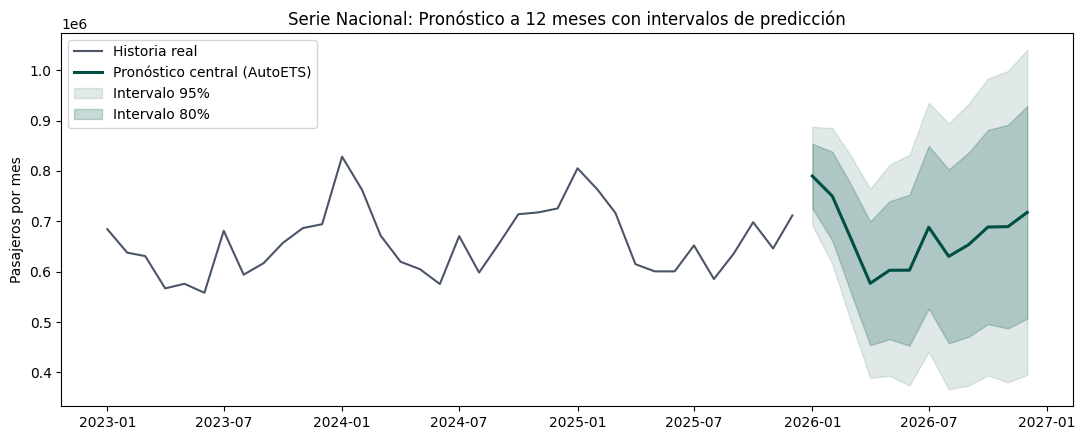

Primer mes pronosticado (2026-01):
  Estimación central : 789,907 pasajeros
  Intervalo 80%      : [725,819 - 853,995]
  Intervalo 95%      : [691,892 - 887,922]


In [12]:
# pronosticamos los próximos 12 meses con intervalos al 80% y 95%
sf_ganador = StatsForecast(models=[AutoETS(season_length=12)], freq='MS')
fc = sf_ganador.forecast(df=df_nac, h=12, level=[80, 95])

hist = df_nac.tail(36).set_index('ds')['y']
f = fc.set_index('ds')

plt.figure(figsize=(11, 4.5))
plt.plot(hist.index, hist.values, color='#4a5568', lw=1.5, label='Historia real')
plt.plot(f.index, f['AutoETS'], color='#004F45', lw=2.2, label='Pronóstico central (AutoETS)')
plt.fill_between(f.index, f['AutoETS-lo-95'], f['AutoETS-hi-95'], color='#004F45', alpha=0.12, label='Intervalo 95%')
plt.fill_between(f.index, f['AutoETS-lo-80'], f['AutoETS-hi-80'], color='#004F45', alpha=0.22, label='Intervalo 80%')
plt.title('Serie Nacional: Pronóstico a 12 meses con intervalos de predicción')
plt.ylabel('Pasajeros por mes'); plt.legend(loc='upper left'); plt.tight_layout(); plt.show()

# valores del primer mes proyectado
primero = f.iloc[0]
print(f"Primer mes pronosticado ({f.index[0].strftime('%Y-%m')}):")
print(f"  Estimación central : {primero['AutoETS']:,.0f} pasajeros")
print(f"  Intervalo 80%      : [{primero['AutoETS-lo-80']:,.0f} - {primero['AutoETS-hi-80']:,.0f}]")
print(f"  Intervalo 95%      : [{primero['AutoETS-lo-95']:,.0f} - {primero['AutoETS-hi-95']:,.0f}]")

**Por qué se hizo así**

- **Por qué las bandas se ensanchan:** predecir el próximo mes es relativamente fácil; predecir qué
  pasará dentro de un año acumula la incertidumbre de todos los meses intermedios. Mientras más lejano el
  horizonte, menor es la certeza.
- **Intervalo 80% vs 95%:** el intervalo del 80% es más estrecho y esperamos que el valor real caiga dentro
  8 de cada 10 veces. El del 95% es más ancho y cubre casi cualquier fluctuación ordinaria.
- **Intervalo de predicción vs intervalo de confianza:** un intervalo de confianza habla del promedio; el
  de predicción habla del **valor individual que observaremos**, por lo que debe incluir también el ruido
  aleatorio inevitable del mundo real.
- **Cautela crítica:** el intervalo asume que el modelo es correcto y que no habrá un nuevo shock global. Si
  ocurre una catástrofe, los datos reales pueden salirse de cualquier banda.

Para revisar cómo se calculan y comunican las bandas de dispersión esperada, consulten la diapositiva [Los intervalos cuantifican la incertidumbre](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/los-intervalos-cuantifican-la-incertidumbre) de la Clase 7 (disponible a continuación de forma interactiva):

In [13]:
# diapositiva interactiva de la clase
from IPython.display import IFrame
IFrame('https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/los-intervalos-cuantifican-la-incertidumbre', width='100%', height=480)

**Si su código no funciona: prompt para que una IA les ayude a corregirlo**

Copien el prompt, reemplacen lo que está entre corchetes y péguenlo en su asistente de IA. Pidan una corrección explicada, no una solución nueva: el objetivo es entender qué falló.

```text
Estoy usando StatsForecast en Python con un modelo AutoETS y generé pronósticos con `level=[80, 95]`.
Tengo un DataFrame con columnas como `AutoETS`, `AutoETS-lo-95`, `AutoETS-hi-95`, etc.
Quiero graficar la historia reciente junto al pronóstico y sus áreas sombreadas de incertidumbre con matplotlib.

Este es mi código:
[pegar aquí su código]

Explícame qué parámetros de `plt.fill_between` debo ajustar para que las bandas se vean semitransparentes y elegantes.
```

### Ejercicio D2 · Decisión operativa de capacidad ante costos asimétricos

Imaginen que son los gerentes de operaciones del aeropuerto de Santiago y deben dimensionar los
turnos del personal de control de seguridad (DGAC), counters y mangas de embarque para el primer mes
proyectado.
Miren las cifras de la celda D1: el pronóstico central (~860.000 pasajeros) y el techo del 95% (~900.000 pasajeros).
Analicen:
1. ¿Cuál es el costo de **subestimar la demanda**? (si dimensionan para 860.000 y llegan 900.000).
2. ¿Cuál es el costo de **sobreestimar la demanda**? (si dimensionan para 900.000 y llegan 860.000).
3. Como en un aeropuerto las filas interminables y la pérdida de vuelos provocan un caos reputacional y
   multas graves, ¿con qué cifra de la banda recomendarían planificar la dotación del personal?

In [14]:
# cifras del primer mes proyectado para evaluar escenarios de capacidad
p_central = primero['AutoETS']
p_piso = primero['AutoETS-lo-95']
p_techo = primero['AutoETS-hi-95']

print("Escenarios para planificar dotación y turnos:")
print(f"  Piso del 95% (Mínimo plausible) : {p_piso:,.0f} pasajeros")
print(f"  Centro      (Lo más probable)   : {p_central:,.0f} pasajeros")
print(f"  Techo del 95%(Máximo plausible) : {p_techo:,.0f} pasajeros")
print(f"  Colchón de seguridad requerido  : {p_techo - p_central:,.0f} pasajeros adicionales (~{((p_techo/p_central)-1)*100:.1f}%)")

# simulador interactivo: cambien la política para ver cuántos turnos se necesitan según el riesgo
import ipywidgets as widgets

def simular_dimensionamiento(politica='Techo del 95% (Protección máxima)', pasajeros_por_turno=5000):
    if politica == 'Piso del 95% (Riesgo alto de colapso)':
        demanda = p_piso
    elif politica == 'Pronóstico central (Lo más probable)':
        demanda = p_central
    elif politica == 'Techo del 80% (Holgura moderada)':
        demanda = primero['AutoETS-hi-80']
    else:
        demanda = p_techo
        
    turnos_necesarios = int(np.ceil(demanda / pasajeros_por_turno))
    colchon = demanda - p_central
    
    print(f"Demanda planificada según política  : {demanda:,.0f} pasajeros")
    print(f"Colchón sobre la estimación central : {colchon:+,.0f} pasajeros ({colchon/p_central*100:+.1f}%)")
    print(f"Turnos de personal requeridos en el mes: {turnos_necesarios} turnos")
    if demanda < p_central:
        print("Alerta: Esta política asume un riesgo severo de colapso y filas si la demanda supera el piso.")
    elif demanda == p_central:
        print("Riesgo moderado: En el 50% de los casos la demanda real superará la capacidad disponible.")
    else:
        print("Política prudente: Absorbe la variabilidad estacional minimizando riesgos operacionales.")

widgets.interact(
    simular_dimensionamiento,
    politica=widgets.Dropdown(
        options=[
            'Piso del 95% (Riesgo alto de colapso)',
            'Pronóstico central (Lo más probable)',
            'Techo del 80% (Holgura moderada)',
            'Techo del 95% (Protección máxima)'
        ],
        value='Techo del 95% (Protección máxima)',
        description='Política:'
    ),
    pasajeros_por_turno=widgets.IntSlider(value=5000, min=1000, max=10000, step=500, description='Capac/Turno:')
)

Escenarios para planificar dotación y turnos:
  Piso del 95% (Mínimo plausible) : 691,892 pasajeros
  Centro      (Lo más probable)   : 789,907 pasajeros
  Techo del 95%(Máximo plausible) : 887,922 pasajeros
  Colchón de seguridad requerido  : 98,015 pasajeros adicionales (~12.4%)


interactive(children=(Dropdown(description='Política:', index=3, options=('Piso del 95% (Riesgo alto de colaps…

<function __main__.simular_dimensionamiento(politica='Techo del 95% (Protección máxima)', pasajeros_por_turno=5000)>

**Por qué se hizo así**

- **Costo de subestimar (quedarse corto):** colapso en los filtros de seguridad, demoras masivas en los
  vuelos, quejas de aerolíneas, pasajeros que pierden conexiones, sanciones de las autoridades y crisis en
  redes sociales. El costo es enorme y no lineal.
- **Costo de sobreestimar (pasarse de largo):** contratar turnos adicionales de personal que tendrán horas
  valle más holgadas. Es un costo monetario acotado y predecible.
- **Criterio de decisión asimétrica:** como quedarse corto cuesta muchísimo más que tener algo de capacidad
  ociosa, la decisión racional **no es dimensionar para el centro (lo más probable)**, sino planificar con
  un **colchón de seguridad cercano al techo del intervalo (percentil 90 u 80-95%)**.
- **La lección:** el rol del pronóstico no es forzar a que el mundo calce con un número, sino entregar al
  tomador de decisiones el mapa de riesgos cuantitativo para gestionar la capacidad.

Para profundizar en la asimetría de consecuencias económicas entre el exceso y el quiebre de stock, revisen la diapositiva [El costo del error es asimétrico](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/el-costo-del-error-es-asimétrico) de la Clase 7.

## Bloque E · Límites del forecasting y ética

No todas las series temporales pueden pronosticarse con éxito.
En este bloque cerramos reflexionando sobre la frontera entre la demanda física y los mercados financieros.

### Ejercicio E1 · Por qué pronosticar demanda no es predecir la bolsa

Esta celda compara conceptualmente la serie de pasajeros aéreos con una serie de precios financieros
(como el precio de una acción bursátil o el tipo de cambio).
Ejecútenla y respondan:
1. ¿Por qué los modelos estadísticos funcionan tan bien con la demanda aérea y fallan estrepitosamente al
   intentar predecir el precio futuro de una acción?
2. ¿Por qué las promesas de "algoritmos de IA para hacerse rico en la bolsa" son casi invariablemente un engaño?

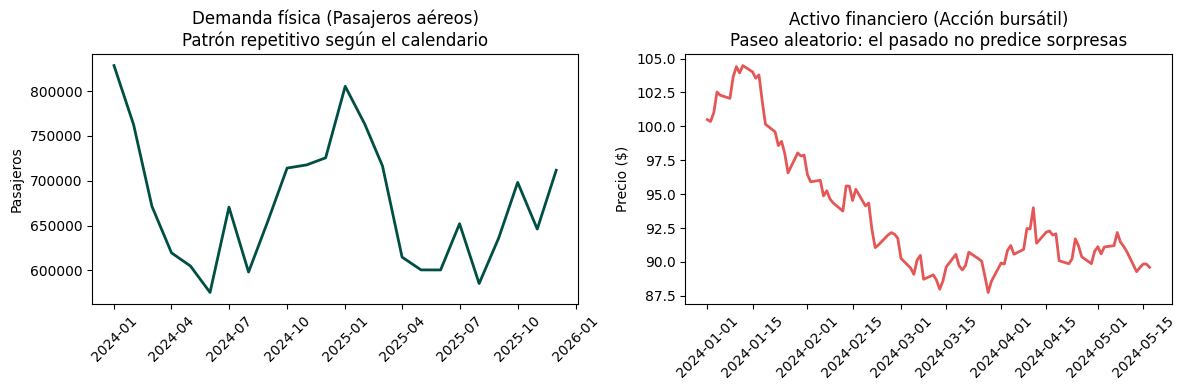

In [15]:
# simulamos una caminata aleatoria típica de una acción bursátil
np.random.seed(42)
pasos = np.random.normal(0, 1, 100)
precio_accion = 100 + np.cumsum(pasos)
fechas_sim = pd.date_range('2024-01-01', periods=100, freq='B')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# 1. demanda física: ciclos humanos y estacionalidad repetible
ax1.plot(hist.index[-24:], hist.values[-24:], color='#004F45', lw=2)
ax1.set_title('Demanda física (Pasajeros aéreos)\nPatrón repetitivo según el calendario')
ax1.set_ylabel('Pasajeros'); ax1.tick_params(axis='x', rotation=45)

# 2. precio financiero: paseo aleatorio dominado por noticias nuevas
ax2.plot(fechas_sim, precio_accion, color='#E45756', lw=2)
ax2.set_title('Activo financiero (Acción bursátil)\nPaseo aleatorio: el pasado no predice sorpresas')
ax2.set_ylabel('Precio ($)'); ax2.tick_params(axis='x', rotation=45)

plt.tight_layout(); plt.show()

**Por qué se hizo así**

- **Por qué la demanda es predecible:** el comportamiento de los pasajeros responde a ciclos humanos
  reales (vacaciones de verano en enero, feriados, jornadas laborales) y capacidades físicas. El pasado sí
  contiene información sobre el futuro.
- **Por qué los precios financieros no:** en un mercado financiero con millones de participantes, la
  información disponible ya está incorporada en el precio actual (hipótesis de mercados eficientes). El
  movimiento de mañana depende de **noticias imprevisibles que aún no han ocurrido** (sorpresas políticas,
  guerras, reportes de utilidades). La serie se comporta como una caminata aleatoria (*random walk*).
- **El baseline imbatible:** en finanzas, el humilde modelo `Naive` ("el precio de mañana será igual al de hoy")
  suele ser prácticamente imposible de superar de forma consistente tras descontar comisiones.
- **Responsabilidad ética:** pronosticar demanda para planificar capacidad logística y recursos humanos es
  una aplicación rigurosa y valiosa de la ciencia de datos. Prometer que un modelo de Machine Learning
  asegura ganancias financieras en el mercado es una promesa vacía que desconoce la naturaleza de los datos.

Para profundizar en los límites empíricos de predecir retornos financieros frente a demanda física, revisen la diapositiva [¿Podemos predecir la bolsa con estos métodos?](https://sebastiancontz.github.io/ust-diplomado-ia-curso-ml/ediciones/2026/clases/07-forecasting.html#/podemos-predecir-la-bolsa-con-estos-métodos) de la Clase 7.

---

## Síntesis formativa

En este repaso 3 de la **Clase 7** dominamos las herramientas fundamentales del forecasting moderno:

1. **Estructura y datos:** entendimos el formato largo estándar (`unique_id`, `ds`, `y`) que permite
   procesar cientos de series en paralelo.
2. **Anatomía visual:** aprendimos a reconocer tendencia, estacionalidad y quiebres estructurales antes
   de escribir una sola línea de modelado.
3. **Líneas base:** incorporamos la regla de oro: ningún modelo complejo se aprueba si no supera a
   `Naive` o `SeasonalNaive`.
4. **Modelos automáticos:** aprovechamos `AutoETS` y `AutoARIMA` en StatsForecast para ajustar modelos
   robustos de forma ágil (*low-code*).
5. **Validación honesta:** reemplazamos el k-fold aleatorio por **ventanas móviles temporales**
   (`cross_validation`), evitando la fuga temporal y evaluando con métricas tangibles (**MAE en pasajeros**
   y **MAPE en %**).
6. **Incertidumbre y decisiones:** comunicamos el pronóstico con **intervalos de predicción (80% y 95%)**
   y dimensionamos la capacidad operativa considerando la **asimetría de costos** entre quedarse corto y pasarse.
7. **Límites éticos:** distinguimos la predictibilidad legítima de la demanda frente al comportamiento
   estocástico de los activos bursátiles.

## Atribución de datos

**Tráfico aéreo de pasajeros en Chile** (`trafico_aereo_cl.csv`)

**Creador:** Junta de Aeronáutica Civil (JAC), Ministerio de Transportes y Telecomunicaciones de Chile.
**Fuente:** [Portal de Datos Abiertos del Gobierno de Chile](https://datos.gob.cl/dataset/trafico-aereo) y
estadísticas mensuales oficiales de la JAC.
**Licencia:** Datos públicos bajo [Licencia CC0 1.0 Universal](https://creativecommons.org/publicdomain/zero/1.0/).
**Modificación:** agregación a nivel mensual para tres series (`internacional`, `nacional`, `total`),
estandarización de nombres de columna al esquema `unique_id`, `ds`, `y` y codificación UTF-8 para uso docente.